# --------------------------------------------------------------
# Code for van der Pol Oscillator example: LSTM architecture
# --------------------------------------------------------------
## This notebook includes:
 - Input signal generation (multisine)
 - Simulation of van der Pol Dynamics and data generation 
 - LSTM prediction model learning using pytorch
 - Model Predictive Control (MPC) simulation using CasADi
# --------------------------------------------------------------

### Import required packages


In [19]:
# Standard libraries
import time
import itertools
import sys

# Scientific computing
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp
from scipy.io import savemat

# Plotting
import matplotlib.pyplot as plt

# Packages used for model learning
import torch
import torch.nn.functional as F
import models  # custom model module

# Optimization (solving the MPC problem)
import casadi as ca

# Functions used in scripts
from functions import van_der_pol, NN, multisine, sigmoid_ca, lstm_cell_ca
 

### Generate input signal used for model learning

(2410,)
(2410,)


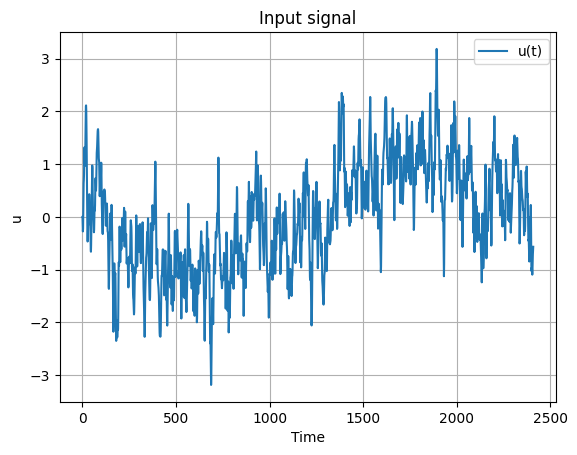

In [20]:
# Length of input signal 
T_period = 2410 

# Generate multisine using custom multisine function from functions.py
u_data = 2*multisine(N_points_per_period=T_period, N_periods=1, pmin=1, pmax=500, n_crest_factor_optim=100,seed=42)

# Generate a single sine 
x = np.linspace(-np.pi, np.pi, T_period)

# Add the multisine to the single sine wave
u_data = u_data + np.sin(x)

# Filter the input signal trough a low pass filter
print(u_data.shape)
u_filtered = np.zeros(len(u_data))
print(u_filtered.shape)
for i in range(0,len(u_data)-1):
    u_filtered[i+1] = 0.9*u_filtered[i] + 0.1*u_data[i]


# Plot the final input signal which will be used to generate the data
plt.plot(u_filtered, label='u(t)')
plt.title('Input signal')
plt.xlabel('Time')
plt.ylabel('u')
plt.legend()
plt.grid()
plt.show()

### Generate output data for the van der Pol Oscillator, used for training

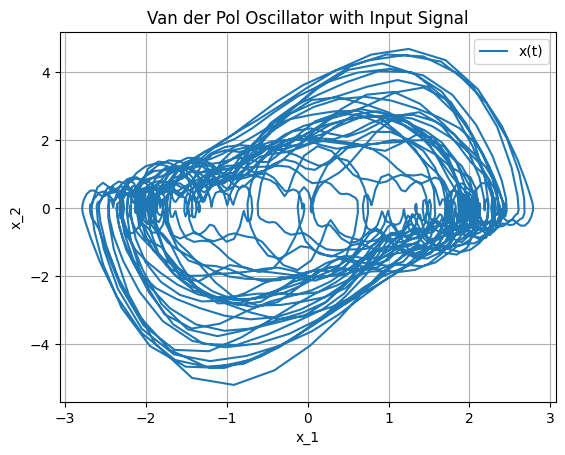

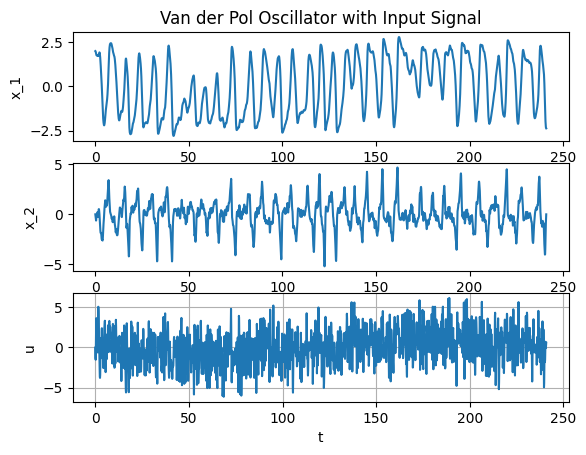

In [21]:
# Parameters
N = 10 # Prediction horizon of the controller
Ts = 0.1 # Sampling time of the controller
mu = 1.0  # You can change this value to see different behaviors of the van der Pol oscillator
y0 = [2, 0]  # Initial conditions: [x0, dx0]

t_vec = [0]
x = [y0]

# Main loop
for i in range(len(u_data)):
    u = u_data[i]
    # Simulate van de Pol Oscillator for 1 sampling period
    sol = solve_ivp(lambda t, y: van_der_pol(t, y, mu, u),[0, Ts], y0, method='RK45')

    # Take the last value as the new initial condition
    y0 = sol.y[:, -1]
    x.append(y0)  # store state
    t_vec.append((i+1) * Ts)  # store time

# Convert list to numpy array for easier plotting
x = np.array(x)
t_vec = np.array(t_vec)

# Plotting
plt.plot(x[:, 0], x[:, 1], label='x(t)')
plt.title('Van der Pol Oscillator with Input Signal')
plt.xlabel('x_1')
plt.ylabel('x_2')
plt.legend()
plt.grid()
plt.show()

# Plotting
plt.subplot(3,1,1)
plt.plot(t_vec, x[:, 0], label='x_1')
plt.title('Van der Pol Oscillator with Input Signal')
plt.ylabel('x_1')
plt.xlabel('t')
plt.subplot(3,1,2)
plt.plot(t_vec, x[:, 1], label='x_2')
plt.ylabel('x_2')
plt.xlabel('t')
plt.subplot(3,1,3)
plt.plot(t_vec[:-1], u_data, label='x_2')
plt.ylabel('u')
plt.xlabel('t')
plt.grid()
plt.show()



### Generate data matrices used for model learning

In [ ]:
# Initialze empty data matrices
X = [] # Initial condition + input data matrix
Y = [] # Output data matrix

# For loop for generating data matrices
for i in range(len(u_data)):
    X_i = np.concatenate(([u_data[i]],x[i, :]))  # Initialize intermediate initial condition data matrix
    X.append(X_i)             # Append X with initial conditions + inputs
    Y.append(x[i + 1, :])     # Append Y with output data

# Convert to numpy arrays 
Y = np.array(Y)
X = np.array(X)

# Divide data into training and validation (2000 samples for training)
X_train = X[0:2000,:]
X_val = X[2000:,:]
Y_train = Y[0:2000,:]
Y_val = Y[2000:,:]

# Optional: print shapes
print("Shapes after split:")
print(f"X_train: {X_train.shape}, X_val: {X_val.shape}")
print(f"Y_train: {Y_train.shape}, Y_val: {Y_val.shape}")



Shapes after split:
X_train: (2000, 3), X_val: (410, 3)
Y_train: (2000, 2), Y_val: (410, 2)


### Train the LSTM model 

In [ ]:
# Define the network dimensions
combinations = [20] # Neurons in hidden layer LSTM, change to [20,30,40] to train multiple combinations
N_epoch = 40000 # Number of epochs used for training the model

# make sure that GPU is used when available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Y_val = np.squeeze(Y_val)  # for numpy array
X_val = np.squeeze(X_val)  # for numpy array
Y_train = np.squeeze(Y_train)  # for numpy array
X_train = np.squeeze(X_train)  # for numpy array

# Convert training data to tensors
X_train = torch.tensor(X_train, dtype=torch.float32).unsqueeze(0).to(device)  
Y_train = torch.tensor(Y_train, dtype=torch.float32).unsqueeze(0).to(device)  

# Convert validation data to tensors
X_val = torch.tensor(X_val, dtype=torch.float32).unsqueeze(0).to(device)      
Y_val = torch.tensor(Y_val, dtype=torch.float32).unsqueeze(0).to(device)      

# Network and data dimensions
input_size = X_train.shape[2]
output_size = Y_train.shape[2]

# Define the training loop using pytorch 
def train(idx, n_hidden, loss_val_i, niter, N_comb):

    # Define LSTM model network
    model = models.LSTMModel(input_size, n_hidden, output_size).to(device)

    # Define the optimizer, learning rate, weight decay
    optimizer = torch.optim.AdamW(
        list(model.parameters()), 
        lr=1e-3,
        weight_decay=1e-4  # L2 regularization (weight decay)
    )

    # Add a learning rate scheduler
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10000, gamma=0.1)

    # Initialize empty list for storing the training and validation loss
    train_loss_hist = []
    val_loss_hist = []
    t0 = time.time()

    for i in range(niter):
        # Training step
        def train_step():
            optimizer.zero_grad() # reset the gradients 
            # Forward pass:
            Y_pred = model(X_train) # Output prediction
            loss = torch.mean((Y_pred - Y_train) ** 2) / torch.mean((Y_train) ** 2) # Calculate training loss 
            # Backward pass: 
            loss.backward()
            # Update parameters
            optimizer.step() 
            return loss

        # Validation step
        def validation_step():
            with torch.no_grad():
                Y_pred = model(X_val)
                loss = torch.mean((Y_pred - Y_val) ** 2) / torch.mean((Y_val) ** 2)
                return loss

        loss_train = train_step() # Perform a training step (includes forward pass, loss calc, backward pass, optimizer step)
        loss_val = validation_step() # Perform a validation step (forward pass + loss calc, no weight updates)
        l_train = loss_train.detach().cpu().numpy() # Move training loss tensor to CPU, detach from graph, convert to NumPy
        l_val = loss_val.detach().cpu().numpy() # Same as above for validation loss

        train_loss_hist.append(l_train) # Append training loss data 
        val_loss_hist.append(l_val) # Append validation loss data 

        current_lr = optimizer.param_groups[0]['lr'] # Get the current learning rate from the optimizer
        current_lr = round(current_lr, 5) # Round the learning rate to 5 decimal places for printing

        # Print usefull information during training:
        if i % 10 == 0:
            print(
                "index: ",
                idx,
                "/ ",
                N_comb,
                "Epoch: ",
                i + 1,
                "Learning rate: ",
                current_lr,
                "Train loss",
                l_train,
                "Val loss",
                l_val,
                flush=True,
            )

        # Save the model every 100 iterations and only when validation loss has decreased
        if i % 100 == 0 and loss_val_i >= l_val:
            loss_val_i = l_val
            l_indx_i = i
            torch.save(model, "data_LSTM/model_LSTM_idx_{}".format(str(int(idx))))

        # Step the learning rate scheduler at the end of each iteration
        scheduler.step()

    t1 = time.time()
    print("Total time: ", t1 - t0, flush=True)
    t_elapsed = t1 - t0

    # Save training and validation losses
    np.save("data_LSTM/train_loss.npy", train_loss_hist, allow_pickle=True)
    np.save("data_LSTM/val_loss.npy", val_loss_hist, allow_pickle=True)

    return np.array(train_loss_hist), np.array(val_loss_hist), l_indx_i, loss_val_i, t_elapsed


# start of the ablation study 
ablation_results = []  # Initialize empty list for storing the ablation results 
idx_i = 0  # Initialize training index 

# Looping through the range of indices 
for n_hidden_i in combinations:
    idx_i += 1
    # Call the train function with the current index
    train_loss_hist_i, val_loss_hist_i, l_indx_opt, loss_val_opt, t_elapsed = train(
        idx=idx_i,
        n_hidden=n_hidden_i,
        loss_val_i=float('inf'),
        niter=N_epoch,
        N_comb = len(combinations)
    )

    # Create a dictionary to store the ablation results
    results = {
        'idx': idx_i,
        'hidden state dimension': n_hidden_i,
        'training loss': train_loss_hist_i,
        'validation loss': val_loss_hist_i,
        'training time': t_elapsed
    }
    
    # Append the results to the ablation_results list
    ablation_results.append(results)



Using device: cpu
index:  1 /  1 Epoch:  1 Learning rate:  0.001 Train loss 1.0990142 Val loss 1.1082181
index:  1 /  1 Epoch:  11 Learning rate:  0.001 Train loss 1.0290836 Val loss 1.0438389
index:  1 /  1 Epoch:  21 Learning rate:  0.001 Train loss 0.96241224 Val loss 0.9813904
index:  1 /  1 Epoch:  31 Learning rate:  0.001 Train loss 0.8937352 Val loss 0.91609514
index:  1 /  1 Epoch:  41 Learning rate:  0.001 Train loss 0.817333 Val loss 0.8418769
index:  1 /  1 Epoch:  51 Learning rate:  0.001 Train loss 0.73035216 Val loss 0.75494367
index:  1 /  1 Epoch:  61 Learning rate:  0.001 Train loss 0.6345258 Val loss 0.65700585
index:  1 /  1 Epoch:  71 Learning rate:  0.001 Train loss 0.5335318 Val loss 0.55263406
index:  1 /  1 Epoch:  81 Learning rate:  0.001 Train loss 0.431683 Val loss 0.44696817
index:  1 /  1 Epoch:  91 Learning rate:  0.001 Train loss 0.33736226 Val loss 0.34839702
index:  1 /  1 Epoch:  101 Learning rate:  0.001 Train loss 0.25696662 Val loss 0.26330507
index

### Convert the ablation results to a .mat file for analysis with MATLAB

Text(0.5, 1.0, 'Training and validation loss')

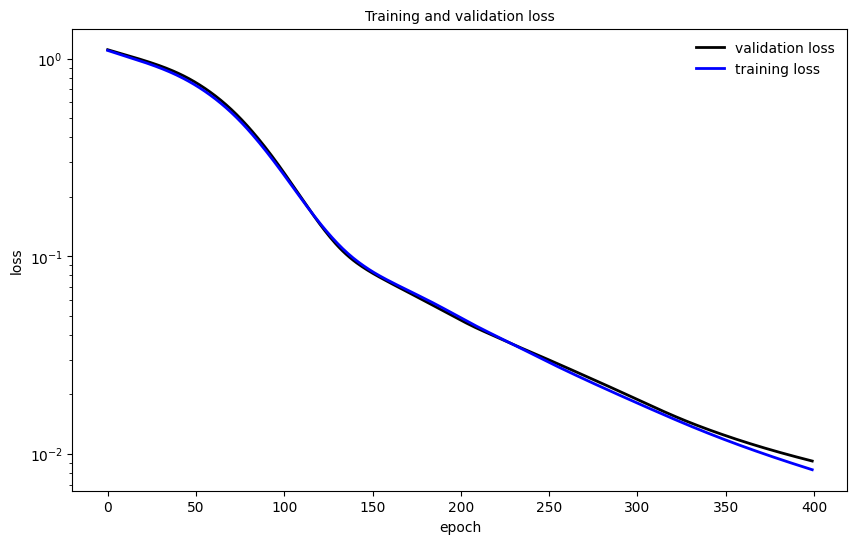

In [23]:
# Prepare dictionary for saving in .mat format
ablation_mat = {}

# Flatten the ablation_results list into a structured dict
for i, result in enumerate(ablation_results):
    ablation_mat[f'result_{i}'] = {
        'idx': result['idx'],
        'hidden_state_dimension': result['hidden state dimension'],
        'train_loss': np.array(result['training loss']),
        'val_loss': np.array(result['validation loss']),
        'T_train': np.array(result['training time'])
    }

# Save the structured dict to a .mat file
savemat("data_LSTM/ablation_results.mat", ablation_mat)

# Make figure
plt.figure(figsize=(10, 6))
for i in range(len(ablation_mat)):
    plt.subplot(len(ablation_mat), 1, i+1)
    plt.semilogy(ablation_mat[f'result_{i}']['val_loss'], '-k', lw=2.0, label="validation loss")
    plt.semilogy(ablation_mat[f'result_{i}']['train_loss'], '-b', lw=2.0, label="training loss")
    plt.xlabel('epoch')
    plt.ylabel('loss')
    plt.legend(frameon=False, loc = 'best')
    
plt.title('Training and validation loss', fontsize = 10)    


### Perform LSTM based MPC simulation

i = 0 / 150
i = 1 / 150
i = 2 / 150
i = 3 / 150
i = 4 / 150
i = 5 / 150
i = 6 / 150
i = 7 / 150
i = 8 / 150
i = 9 / 150
i = 10 / 150
i = 11 / 150
i = 12 / 150
i = 13 / 150
i = 14 / 150
i = 15 / 150
i = 16 / 150
i = 17 / 150
i = 18 / 150
i = 19 / 150
i = 20 / 150
i = 21 / 150
i = 22 / 150
i = 23 / 150
i = 24 / 150
i = 25 / 150
i = 26 / 150
i = 27 / 150
i = 28 / 150
i = 29 / 150
i = 30 / 150
i = 31 / 150
i = 32 / 150
i = 33 / 150
i = 34 / 150
i = 35 / 150
i = 36 / 150
i = 37 / 150
i = 38 / 150
i = 39 / 150
i = 40 / 150
i = 41 / 150
i = 42 / 150
i = 43 / 150
i = 44 / 150
i = 45 / 150
i = 46 / 150
i = 47 / 150
i = 48 / 150
i = 49 / 150
i = 50 / 150
i = 51 / 150
i = 52 / 150
i = 53 / 150
i = 54 / 150
i = 55 / 150
i = 56 / 150
i = 57 / 150
i = 58 / 150
i = 59 / 150
i = 60 / 150
i = 61 / 150
i = 62 / 150
i = 63 / 150
i = 64 / 150
i = 65 / 150
i = 66 / 150
i = 67 / 150
i = 68 / 150
i = 69 / 150
i = 70 / 150
i = 71 / 150
i = 72 / 150
i = 73 / 150
i = 74 / 150
i = 75 / 150
i = 76 / 150
i = 77 / 

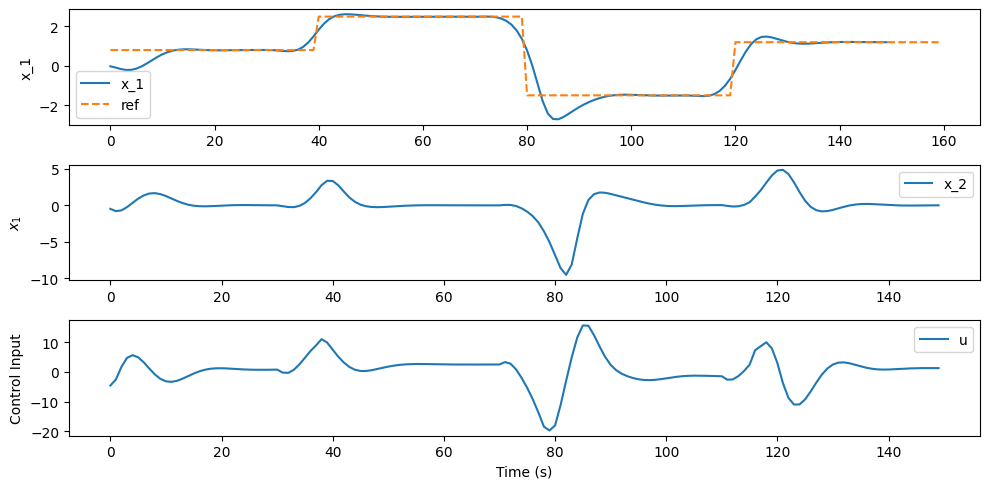

In [ ]:
# select optimal index based on the minimal validation loss in ablation_results:
idx_opt = 1 # change to correct index as defined in the code block: Train the LSTM model 
model = torch.load("data_LSTM/model_LSTM_idx_{}".format(str(int(idx_opt))), map_location=torch.device('cpu'), weights_only=False)

# Get weights and biases from PyTorch LSTM layer
W_ih = ca.DM(model.lstm.weight_ih_l0.detach().cpu().numpy()) 
W_hh = ca.DM(model.lstm.weight_hh_l0.detach().cpu().numpy()) 
b_ih = ca.DM(model.lstm.bias_ih_l0.detach().cpu().numpy())   
b_hh = ca.DM(model.lstm.bias_hh_l0.detach().cpu().numpy())   
b = b_ih + b_hh

# Get weights and biases from the output layer of the LSTM
W_fc = ca.DM(model.fc.weight.detach().cpu().numpy())
b_fc = ca.DM(model.fc.bias.detach().cpu().numpy())


# System dimensions van der Pol oscillator
nx = 2 # [theta, theta_dot]
ny = 1 # [theta]
nu = 1 # [u]

n_hidden = 20 # Select here correct number of neurons hidden layer LSTM model with index idx_opt

# MPC cost function matrices
Q = np.eye(N*ny) * 100
R = np.eye(N * nu)

# Define constant pieces for reference signal
ref1 = np.tile([0.8], (40, 1))     
ref2 = np.tile([2.5], (40, 1))    
ref3 = np.tile([-1.5], (40, 1))     
ref4 = np.tile([1.2], (40, 1))     

# Concatenate them along the first axis (time steps)
xref_traj = np.concatenate((ref1, ref2, ref3,ref4), axis=0)  
xref_traj = xref_traj.flatten().reshape(-1, 1)

# CasADi setup
opti = ca.Opti()
h = opti.variable(n_hidden, N+1)
c = opti.variable(n_hidden, N+1)
x = opti.variable(nx, N+1)
y = opti.variable(ny,N)
u = opti.variable(nu*N, 1)
du = opti.variable(nu*N, 1)

# Parameters
x0 = opti.parameter(nx, 1)
h0 = opti.parameter(n_hidden, 1)
c0 = opti.parameter(n_hidden, 1)

u0 = opti.parameter(nu, 1)
ref = opti.parameter(ny,N)

# Cost
x_flat = ca.reshape(x[:, 1:], nx * N, 1)
cost = ca.mtimes([(y - ref), Q, (y - ref).T]) + ca.mtimes([du.T, R, du])
opti.minimize(cost)

# Initial states
opti.subject_to(h[:,0] == h0)
opti.subject_to(c[:,0] == c0)
opti.subject_to(y[0,:] == x[0,1:])
opti.subject_to(x[:,0] == x0)

# Prediction loop
for i in range(N):

    # Apply the LSTM step
    y_next, h_next, c_next = lstm_cell_ca(ca.vertcat(u[i], x[:,i]), h[:,i], c[:,i], W_ih, W_hh, b, W_fc, b_fc)
    
    # Add constraints to the optimizer
    opti.subject_to(x[:, i+1] == y_next)
    opti.subject_to(h[:, i+1] == h_next)
    opti.subject_to(c[:, i+1] == c_next) 
   
# Delta u constraints
opti.subject_to(du[0:nu] == u[0:nu] - u0)
opti.subject_to(du[nu:] == u[nu:] - u[:-nu])

# Solver
opti.solver('ipopt', {'ipopt.print_level': 0, 'print_time': 0})

x_vals = [] # Initialize empty list for storing state data
u_vals = [] # Initialize empty list for storing input data
solve_times = []  # Initialize empty list to store time per control action 

h_current = np.zeros(n_hidden)
c_current = np.zeros(n_hidden)
x_current = np.array([0.0, 0.0])  # Initial conditions for van de Pol oscillator
u_mpc = 0 # Initial condition for input (needed for \delta u(0))

for i in range(len(xref_traj)-N):
    print(f'i = {i} / {len(xref_traj)-N}')
    REF = xref_traj[i:i+N,:].T # Define current reference signal 

    opti.set_value(h0, h_current) # Initialize hidden state 
    opti.set_value(c0, c_current) # Initialize cell state 
    opti.set_value(x0, x_current) # Initialize initial condition
    opti.set_value(u0, u_mpc) # Initialize initial input (u_{k-1})
    opti.set_value(ref, REF) # Initialize reference signal 

    start = time.perf_counter()
    sol = opti.solve()
    elapsed = time.perf_counter() - start
    solve_times.append(elapsed)  # Store each solve time

    u_mpc = sol.value(u[0]) # Exctract current input, to be applied to the system 
    # Hidden state and cell state for next sampling time 
    h_current = sol.value(h[:,1])
    c_current = sol.value(c[:,1])
    
    # Apply input to van der pol oscillator and simulate for Ts seconds
    sol = solve_ivp(lambda t, y: van_der_pol(t, y, mu, u_mpc),[0, Ts], x_current, method='RK45')

    # Take the last value as the new initial condition
    x_next = sol.y[:, -1] # measured state at t = (i+1)T_s
    x_vals.append(x_next) # Append state data vector
    u_vals.append(u_mpc) # Append input data vector
    x_current = x_next # Initialize new current state for next iteration

solve_times = np.array(solve_times) # Convert control times to numpy array 
x_vals = np.array(x_vals) # Convert state data to numpy array 
u_vals = np.array(u_vals) # Convert input data to numpy array 
t_vec = np.arange(len(xref_traj)-N) * Ts # Define time vector

# Make figure of the closed--loop response
plt.figure(figsize=(10, 5))
plt.subplot(3, 1, 1)
plt.plot(x_vals[:, 0], label='x_1')
plt.plot(xref_traj, label='ref', linestyle='--')
plt.ylabel("x_1")
plt.legend()

plt.subplot(3, 1, 2)
plt.plot(x_vals[:, 1], label='x_2')
plt.ylabel("$x_1$")
plt.legend()

plt.subplot(3, 1, 3)
plt.plot(u_vals, label='u')
plt.xlabel("Time (s)")
plt.ylabel("Control Input")
plt.legend()

plt.tight_layout()
plt.show()


## save MPC results a .mat files for analysis in Matlab

In [25]:
# Put MPC results in a dictionary with variable names
data_to_save = {
    "x_vals_LSTM": x_vals,
    "u_vals_LSTM": u_vals,
    "solve_times_LSTM": solve_times,
    "xref_traj_LSTM": xref_traj    
}

# Save to a .mat file
savemat('data_LSTM/LSTM_vdp.mat', data_to_save)
print("Arrays saved to 'LSTM_vdp.mat'")



Arrays saved to 'LSTM_vdp.mat'
